# LAB3 - Bài 6 (Trang 26): Dùng k-Means giảm số màu để giảm kích thước ảnh
**Đinh Nhật Huyền Nhân - 6451071055 - CQ.64.CNTT**

In [1]:
print("Đinh Nhật Huyền Nhân - 6451071055")
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.cluster import KMeans
from sklearn.utils import shuffle
print("Đã khai báo thư viện.")

Đinh Nhật Huyền Nhân - 6451071055


Đã khai báo thư viện.


Đinh Nhật Huyền Nhân - 6451071055


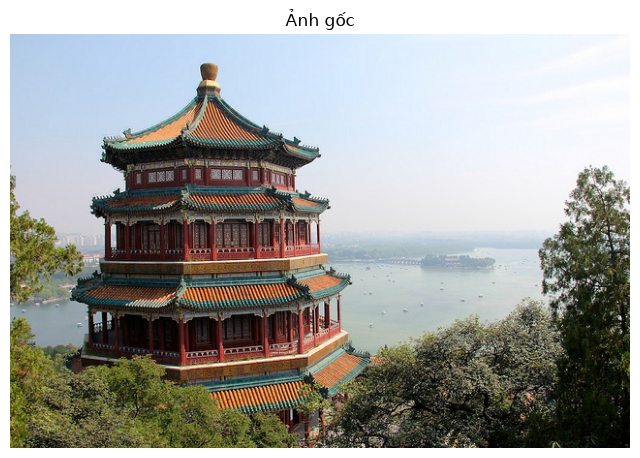

Dung lượng file ảnh gốc: 479.4 KB


In [2]:
print("Đinh Nhật Huyền Nhân - 6451071055")
duong_dan = "anh_goc.png"
anh = Image.open(duong_dan).convert("RGB")
plt.figure(figsize=(8, 6)); plt.imshow(anh); plt.axis("off"); plt.title("Ảnh gốc"); plt.show()
print("Dung lượng file ảnh gốc:", round(os.path.getsize(duong_dan) / 1024, 1), "KB")

In [3]:
print("Đinh Nhật Huyền Nhân - 6451071055")
anh_arr = np.array(anh)
w, h, d = anh_arr.shape
print("Kích thước mảng ảnh (cao, rộng, số kênh màu):", anh_arr.shape)
print("Số màu khác nhau trong ảnh gốc:", len(np.unique(anh_arr.reshape(-1, 3), axis=0)))

Đinh Nhật Huyền Nhân - 6451071055
Kích thước mảng ảnh (cao, rộng, số kênh màu): (427, 640, 3)


Số màu khác nhau trong ảnh gốc: 96615


In [4]:
print("Đinh Nhật Huyền Nhân - 6451071055")
anh_01 = anh_arr.astype(np.float64) / 255.0
mang_2d = anh_01.reshape(w * h, d)
print("Mảng 2 chiều (cao x rộng, sâu):", mang_2d.shape)
print("Min / Max:", mang_2d.min(), mang_2d.max())

Đinh Nhật Huyền Nhân - 6451071055
Mảng 2 chiều (cao x rộng, sâu): (273280, 3)
Min / Max: 0.0 1.0


In [5]:
print("Đinh Nhật Huyền Nhân - 6451071055")
so_mau = 32
kmeans = KMeans(n_clusters=so_mau, max_iter=300, random_state=42)
kmeans.fit(mang_2d)
nhan = kmeans.predict(mang_2d)                                      # mỗi điểm ảnh -> màu (tâm cụm) gần nhất
mang_moi = kmeans.cluster_centers_[nhan]
print("Bảng màu sau gom cụm:", kmeans.cluster_centers_.shape)
print("Mảng ảnh sau gom cụm:", mang_moi.shape)

Đinh Nhật Huyền Nhân - 6451071055


Bảng màu sau gom cụm: (32, 3)
Mảng ảnh sau gom cụm: (273280, 3)


In [6]:
print("Đinh Nhật Huyền Nhân - 6451071055")
anh_moi = mang_moi.reshape(w, h, d)
print("Kích thước ảnh sau khôi phục:", anh_moi.shape)

Đinh Nhật Huyền Nhân - 6451071055
Kích thước ảnh sau khôi phục: (427, 640, 3)


Đinh Nhật Huyền Nhân - 6451071055


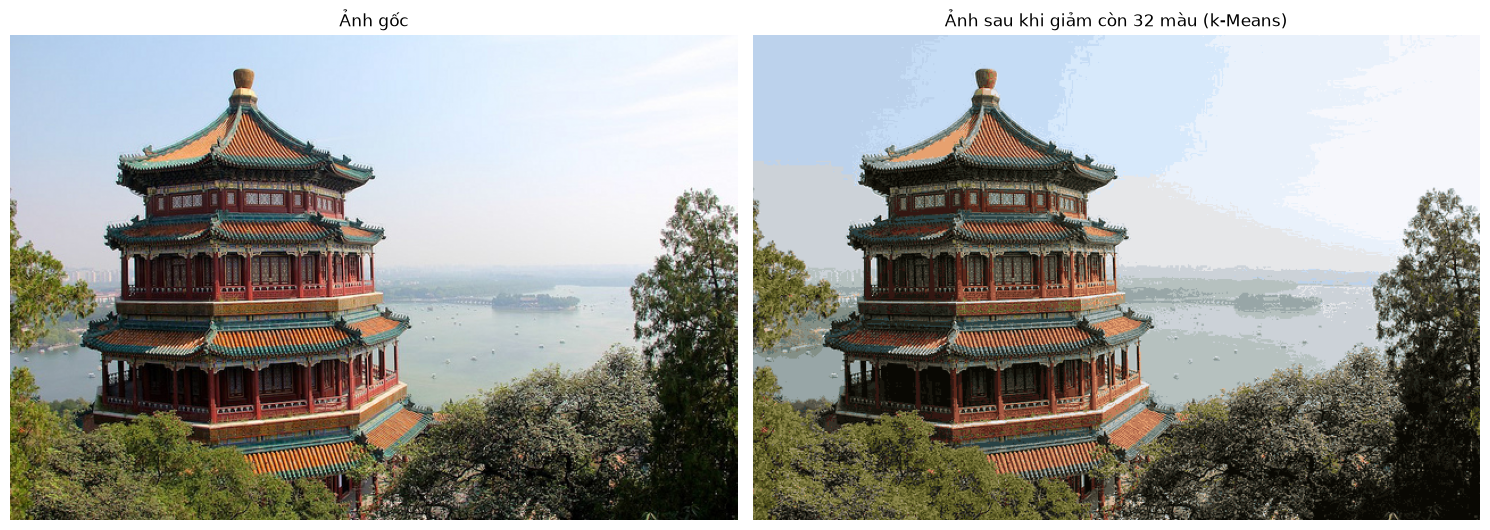

In [7]:
print("Đinh Nhật Huyền Nhân - 6451071055")
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
ax[0].imshow(anh_01); ax[0].set_title("Ảnh gốc"); ax[0].axis("off")
ax[1].imshow(anh_moi); ax[1].set_title(f"Ảnh sau khi giảm còn {so_mau} màu (k-Means)"); ax[1].axis("off")
plt.tight_layout(); plt.show()

In [8]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# Lưu dạng ảnh bảng màu (PNG palette): mỗi điểm ảnh lưu chỉ số cụm, bảng màu = 32 tâm cụm của k-Means
anh_ket_qua = Image.fromarray(nhan.reshape(w, h).astype(np.uint8), mode="P")
anh_ket_qua.putpalette((kmeans.cluster_centers_ * 255).round().astype(np.uint8).flatten().tolist())
anh_ket_qua.save("anh_32_mau.png", optimize=True)
kb_goc = os.path.getsize("anh_goc.png") / 1024
kb_moi = os.path.getsize("anh_32_mau.png") / 1024
print(f"Ảnh gốc     : anh_goc.png    - {kb_goc:8.1f} KB")
print(f"Ảnh 32 màu  : anh_32_mau.png - {kb_moi:8.1f} KB")
print(f"Giảm được {100 * (1 - kb_moi / kb_goc):.1f}% dung lượng")

Đinh Nhật Huyền Nhân - 6451071055
Ảnh gốc     : anh_goc.png    -    479.4 KB
Ảnh 32 màu  : anh_32_mau.png -     74.9 KB
Giảm được 84.4% dung lượng


- Ảnh gốc 427x640 có khoảng 96.600 màu khác nhau. Sau khi k-Means gom các điểm ảnh thành 32 cụm màu, mỗi điểm ảnh được thay bằng màu của tâm cụm gần nhất.
- Bằng mắt thường, ảnh 32 màu gần như giống ảnh gốc; chỉ các vùng chuyển màu mịn (bầu trời) có hiện tượng phân dải màu nhẹ.
- File PNG sau khi giảm màu (lưu dạng bảng màu 32 màu) chỉ còn khoảng 75 KB so với 479 KB của ảnh gốc, giảm khoảng 84% dung lượng. Muốn giảm thêm dung lượng thì giảm số cụm k, đổi lại chất lượng ảnh sẽ giảm.